# Opdracht 2: Voorspel verhuuraantallen

**Teamnaam: Bakabana pindasaus**

Aroetin Avanesi, aroetin 25103865

Moreo Rahiembaks, moreorahiembaks, 25107607

Kaylim Taai, kaylimtaai, 24093157

## Inhoudsopgave
1. Inleiding
2. Exploratieve Data Analyse
3. Time series feature engineering
4. Modelleren
5. Bevindingen
6. Conclusie en aanbevelingen
7. Referenties

## 1. Inleiding

CityBike verhuurt fietsen op verschillende locaties in een grote stad. Klanten kunnen op ieder moment van de dag een fiets huren, bijvoorbeeld om naar hun werk te gaan, om de stad te bekijken of gewoon om een stukje te fietsen. Voor CityBike is het daarom belangrijk om te weten hoeveel fietsen er op ieder moment nodig zijn. Staan er te weinig fietsen, dan kan een klant geen fiets huren en loopt CityBike omzet mis. Staan er juist te veel fietsen op één plek, dan worden de fietsen en stallingsplaatsen niet goed benut.

Wat ons opviel toen we de data bekeken, is dat deze sterk lijkt op de bekende Bike Sharing dataset van Capital Bikeshare in Washington D.C. (Fanaee-T & Gama, 2014). De kolommen, de periode (2011 en 2012) en de feestdagen komen namelijk precies overeen. Dat is handig, want zo kunnen we de genormaliseerde weerkolommen terugrekenen naar echte eenheden (zie 2.2) en opvallende momenten in de data verklaren.

In dit notebook beginnen we met een verkenning van de data (hoofdstuk 2). Daarna maken we nieuwe features op basis van de tijd (hoofdstuk 3) en vergelijken we verschillende modellen (hoofdstuk 4). Vervolgens zetten we de resultaten op een rij (hoofdstuk 5) en sluiten we af met onze conclusie en een advies aan CityBike (hoofdstuk 6).

### 1.1 Probleemstelling

CityBike wil weten **hoeveel fietsen er per uur worden verhuurd** (`cnt`). We trainen op de periode van 1 januari 2011 tot en met 30 november 2012 en voorspellen de periode van **1 tot en met 19 december 2012**.

Dit is een regressieprobleem, maar wel een bijzonder soort: de data is een tijdreeks. Dat heeft drie gevolgen voor onze aanpak:

1. **De volgorde in de tijd is belangrijk.** Bij het valideren mogen we nooit trainen op data die na de validatieperiode ligt. Anders "kijkt" het model immers in de toekomst. Daarom gebruiken we geen gewone KFold, maar een cross-validation die rekening houdt met de tijd (hoofdstuk 4.1).
2. **We voorspellen 19 dagen vooruit.** Voor de testperiode kennen we `cnt` niet. Een feature als "het aantal verhuringen van een uur geleden" kunnen we daar dus niet gebruiken. Daar houden we rekening mee bij de feature engineering (hoofdstuk 3.3).
3. **De score is de RMSE.** Kaggle beoordeelt ons op de Root Mean Squared Error, oftewel hoeveel fietsen we er gemiddeld naast zitten, waarbij grote fouten zwaarder tellen. De minimumeis is een RMSE van 80.

Uiteindelijk willen we een model dat CityBike helpt om de fietsen beter te verdelen, zodat klanten zo vaak mogelijk een fiets kunnen huren wanneer ze die nodig hebben.

## 2. Exploratieve Data Analyse

### 2.1 Data inladen

In [59]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Vaste kleuren, zodat dezelfde groep in iedere grafiek dezelfde kleur heeft
BLUE = "#257de0"
ORANGE = "#f47230"
sns.set_theme(style="whitegrid")

TARGET = "cnt"
WEATHER_COLS = ["temp", "atemp", "hum", "windspeed"]


class BikeData:
    """Laadt de datasets van de Kaggle competitie Voorspel verhuuraantallen."""

    def __init__(self, data_dir="voorspel-verhuuraantallen-2026"):
        # Map waarin de csv bestanden staan (in de GitHub repo)
        self.data_dir = Path(data_dir)
        self.train = None
        self.test = None
        self.submission = None

    def load(self):
        """Leest de drie csv bestanden in en zet date_hour om naar datetime."""
        self.train = pd.read_csv(self.data_dir / "train.csv",
                                 parse_dates=["date_hour"])
        self.test = pd.read_csv(self.data_dir / "test.csv",
                                parse_dates=["date_hour"])
        self.submission = pd.read_csv(
            self.data_dir / "sample_submission.csv"
        )
        return self

    def check_shapes(self):
        """Toont het aantal rijen en kolommen en de periode per dataset."""
        for name, df in [("train", self.train), ("test", self.test)]:
            print(f"{name:<6} {df.shape}  "
                  f"{df['date_hour'].min()} t/m {df['date_hour'].max()}")
        print(f"submission {self.submission.shape}")


data = BikeData().load()
data.check_shapes()
data.train.head()

train  (16637, 8)  2011-01-01 00:00:00 t/m 2012-11-30 23:00:00
test   (456, 7)  2012-12-01 00:00:00 t/m 2012-12-19 23:00:00
submission (456, 2)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


### 2.2 Uitleg kolommen

De weerkolommen zijn genormaliseerd, oftewel omgezet naar een waarde tussen 0 en 1. Volgens de beschrijving van de originele dataset (Fanaee-T, 2013) kun je ze op de manier hieronder terugrekenen naar echte eenheden. Dat doen we in de grafieken, omdat "20 °C" nu eenmaal makkelijker te lezen is dan "0,6".

| Kolom | Betekenis | Type | Terugrekenen |
|---|---|---|---|
| `date_hour` | Datum en uur van de meting | datetime | |
| `holiday` | 1 = officiële feestdag in Washington D.C., 0 = geen feestdag | binair | |
| `weathersit` | Weertype: 1 = helder, 2 = mist of bewolkt, 3 = lichte regen of sneeuw, 4 = zware regen, hagel of sneeuw | categorisch (geordend) | |
| `temp` | Temperatuur | continu | $t = temp \cdot 47 - 8$ (°C) |
| `atemp` | Gevoelstemperatuur | continu | $t = atemp \cdot 66 - 16$ (°C) |
| `hum` | Luchtvochtigheid | continu | $hum \cdot 100$ (%) |
| `windspeed` | Windsnelheid | continu | $windspeed \cdot 67$ (km/u) |
| `cnt` | **Target:** aantal verhuurde fietsen in dat uur | geheel getal | |

Een kanttekening bij `weathersit`: het is een getal, maar eigenlijk een categorie. Wel een categorie met een volgorde, want hoe hoger het getal, hoe slechter het weer. Een model mag daarom ook rekenen met "hoger = slechter".

In [60]:
def describe_columns(df):
    """Datatype, aantal unieke waarden, bereik en voorbeelden per kolom."""
    return pd.DataFrame({
        "datatype": df.dtypes.astype(str),
        "uniek": df.nunique(),
        "minimum": df.min(),
        "maximum": df.max(),
        "voorbeeld": df.iloc[0],
    })


describe_columns(data.train)

,datatype,uniek,minimum,maximum,voorbeeld
date_hour,datetime64[us],16637,2011-01-01 00:00:00,2012-11-30 23:00:00,2011-01-01 00:00:00
holiday,int64,2,0,1,0
weathersit,int64,4,1,4,1
temp,float64,50,0.02,1.0,0.24
atemp,float64,65,0.0,1.0,0.2879
hum,float64,89,0.0,1.0,0.81
windspeed,float64,30,0.0,0.8507,0.0
cnt,int64,867,1,977,16


### 2.3 Datatypes en basisstatistieken

In [61]:
def show_overview(df):
    """Toont het formaat, ontbrekende waarden en dubbele rijen."""
    print(f"Rijen: {df.shape[0]}, kolommen: {df.shape[1]}")
    print(f"Ontbrekende waarden: {df.isna().sum().sum()}")
    print(f"Dubbele rijen: {df.duplicated().sum()}")


show_overview(data.train)
print(data.train.dtypes)
# Gemiddelde, spreiding, minimum, kwartielen en maximum
data.train.describe().round(3)

Rijen: 16637, kolommen: 8
Ontbrekende waarden: 0
Dubbele rijen: 0
date_hour     datetime64[us]
holiday                int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
cnt                    int64
dtype: object


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000
mean,2011-12-18 02:20:08.294764,0.029,1.416,0.505,0.483,0.625,0.190,190.477
min,2011-01-01 00:00:00,0.000,1.000,0.020,0.000,0.000,0.000,1.000
25%,2011-06-27 05:00:00,0.000,1.000,0.340,0.333,0.470,0.104,41.000
50%,2011-12-18 06:00:00,0.000,1.000,0.520,0.500,0.620,0.194,143.000
75%,2012-06-09 02:00:00,0.000,2.000,0.660,0.621,0.780,0.254,282.000
max,2012-11-30 23:00:00,1.000,4.000,1.000,1.000,1.000,0.851,977.000
std,NaN,0.167,0.637,0.192,0.172,0.193,0.122,182.027


In [62]:
def count_values(df, columns):
    """Aantal en percentage per waarde voor categorische kolommen."""
    tables = []
    for col in columns:
        counts = df[col].value_counts().sort_index()
        tables.append(pd.DataFrame({
            "kolom": col,
            "waarde": counts.index,
            "aantal": counts.values,
            "percentage": (counts.values / len(df) * 100).round(2),
        }))
    return pd.concat(tables, ignore_index=True)


count_values(data.train, ["holiday", "weathersit"])

,kolom,waarde,aantal,percentage
0,holiday,0,16160,97.13
1,holiday,1,477,2.87
2,weathersit,1,11078,66.59
3,weathersit,2,4207,25.29
4,weathersit,3,1349,8.11
5,weathersit,4,3,0.02


Verwacht aantal uren: 16800
Ontbrekende uren:     163
Laagste waarde cnt:   1


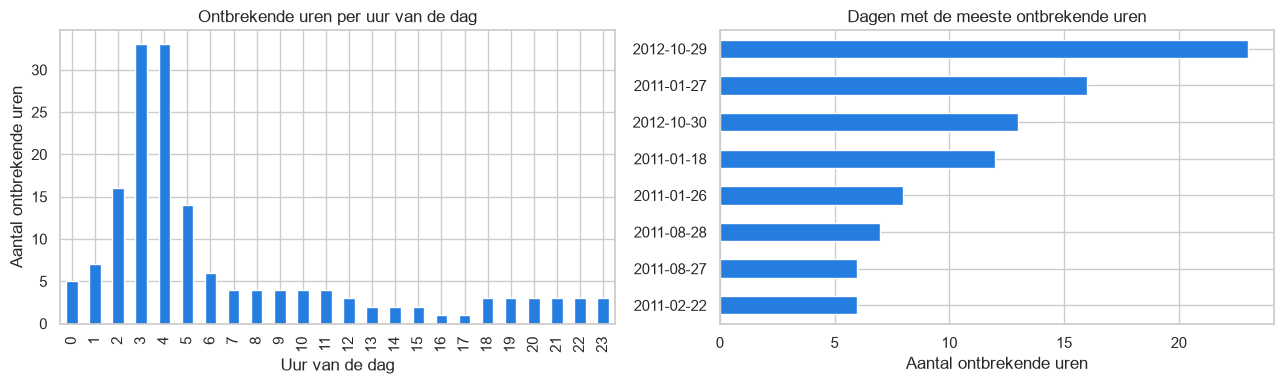

In [63]:
def find_missing_hours(df):
    """Geeft alle uren terug die in de reeks ontbreken."""
    full_range = pd.date_range(df["date_hour"].min(),
                               df["date_hour"].max(), freq="h")
    return full_range.difference(df["date_hour"])


missing = find_missing_hours(data.train)
print(f"Verwacht aantal uren: {len(missing) + len(data.train)}")
print(f"Ontbrekende uren:     {len(missing)}")
print(f"Laagste waarde cnt:   {data.train[TARGET].min()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(missing.hour).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=BLUE)
axes[0].set_title("Ontbrekende uren per uur van de dag")
axes[0].set_xlabel("Uur van de dag")
axes[0].set_ylabel("Aantal ontbrekende uren")

pd.Series(missing.date).value_counts().head(8).sort_values().plot(
    kind="barh", ax=axes[1], color=BLUE)
axes[1].set_title("Dagen met de meeste ontbrekende uren")
axes[1].set_xlabel("Aantal ontbrekende uren")
plt.tight_layout()
plt.show()

In [64]:
def check_weather(df):
    """Telt verdachte waarden in de weerkolommen per dag."""
    temp_c = df["temp"] * 47 - 8
    atemp_c = df["atemp"] * 66 - 16
    checks = {
        "hum == 0": df["hum"] == 0,
        "windspeed == 0": df["windspeed"] == 0,
        "|temp - atemp| > 10 °C": (temp_c - atemp_c).abs() > 10,
    }
    for name, mask in checks.items():
        days = df.loc[mask, "date_hour"].dt.date.value_counts()
        print(f"{name:<24} {mask.sum():>5} uren, "
              f"vaakst op: {days.head(3).to_dict()}")


check_weather(data.train)

hum == 0                    22 uren, vaakst op: {datetime.date(2011, 3, 10): 22}
windspeed == 0            2072 uren, vaakst op: {datetime.date(2011, 10, 7): 20, datetime.date(2012, 11, 26): 16, datetime.date(2011, 12, 11): 15}
|temp - atemp| > 10 °C      37 uren, vaakst op: {datetime.date(2012, 8, 17): 24, datetime.date(2011, 7, 21): 7, datetime.date(2011, 7, 22): 6}


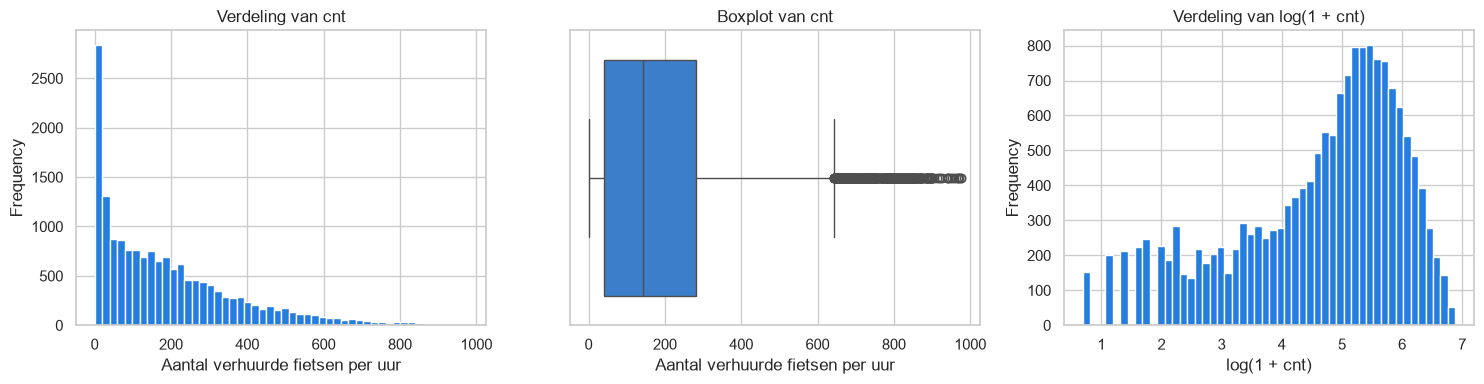

Scheefheid (skewness): 1.28
Outliers volgens de IQR-regel (cnt > 644): 486


In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data.train[TARGET].plot(kind="hist", bins=50, ax=axes[0], color=BLUE)
axes[0].set_title("Verdeling van cnt")
axes[0].set_xlabel("Aantal verhuurde fietsen per uur")

sns.boxplot(x=data.train[TARGET], ax=axes[1], color=BLUE)
axes[1].set_title("Boxplot van cnt")
axes[1].set_xlabel("Aantal verhuurde fietsen per uur")

np.log1p(data.train[TARGET]).plot(kind="hist", bins=50, ax=axes[2],
                                  color=BLUE)
axes[2].set_title("Verdeling van log(1 + cnt)")
axes[2].set_xlabel("log(1 + cnt)")
plt.tight_layout()
plt.show()

q1, q3 = data.train[TARGET].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Scheefheid (skewness): {data.train[TARGET].skew():.2f}")
print(f"Outliers volgens de IQR-regel (cnt > {upper:.0f}): "
      f"{(data.train[TARGET] > upper).sum()}")

**Wat hebben we gecontroleerd en wat zien we?**

Eerst hebben we gekeken naar de datatypes en basisstatistieken. Daarna hebben we gecontroleerd of er uren ontbreken en of er vreemde waarden in het weer zitten. Tot slot hebben we de verdeling van `cnt` bekeken.

* **Datatypes.** De dataset heeft 16.637 rijen en 8 kolommen: `date_hour` (datetime), `holiday`, `weathersit` en `cnt` (gehele getallen) en vier weerkolommen (kommagetallen). Er zijn geen lege cellen en geen dubbele rijen of tijdstippen.
* **Er ontbreken 163 uren.** Er staan dan wel geen lege cellen in de data, maar bij een tijdreeks kunnen er ook hele rijen ontbreken. Van 1 januari 2011 tot en met 30 november 2012 zouden er 16.800 uren moeten zijn. Wat ons hierbij opviel, is dat `cnt` nooit 0 is. Het minimum is namelijk 1. De vraag is dan: wat gebeurt er met een uur waarin niemand een fiets huurt? Als we kijken wanneer de uren ontbreken, zien we dat dit bijna altijd 's nachts is, vooral tussen 2:00 en 5:00. Onze verklaring is dat zo'n uur gewoon niet in de data is opgenomen. Een ontbrekend uur betekent dus waarschijnlijk **0 verhuringen**, en niet dat de meting mist.
* **Twee grote gaten hebben een verklaring.** Op 29 en 30 oktober 2012 ontbreken 36 uren. Toen ging Capital Bikeshare dicht vanwege orkaan Sandy (Bates Area Civic Association, 2012). Ook in januari 2011 en op 27 en 28 augustus 2011, toen orkaan Irene langs de oostkust trok, ontbreken veel uren. Dit zijn uitzonderingen die het model niet hoeft te leren.
* **`weathersit` 4 komt maar 3 keer voor.** Van zo weinig voorbeelden kan een model niets leren (zie 2.7).
* **Er zitten fouten in de weerdata.** Een luchtvochtigheid van 0% kan niet, maar komt op 10 maart 2011 een hele dag voor. Daarnaast ligt `atemp` op 17 augustus 2012 de hele dag meer dan 10 °C onder `temp`. Dit zijn meetfouten die we in 2.7 herstellen. Een windsnelheid van 0 komt 2.072 keer voor. Dat kan windstil zijn, maar ook een ontbrekende meting. Omdat we dat niet kunnen controleren, laten we deze waarden staan.
* **`cnt` is scheef naar rechts verdeeld** (skewness 1,28). De meeste uren hebben weinig verhuringen en er zijn een paar uren met heel veel. De IQR-regel noemt 486 van die drukke uren outliers, maar dat zijn gewoon de spitsuren. Die verwijderen we dus niet. Na een log-transformatie is de verdeling een stuk minder scheef. Of dat de voorspellingen beter maakt, proberen we uit bij het modelleren (hoofdstuk 4).

### 2.4 Tijdserie-elementen en patronen

We voegen eerst een aantal tijdselementen toe aan de data: uur, weekdag, maand, jaar en `workingday`. Een werkdag is een dag die geen zaterdag, zondag of feestdag is. We verwachten namelijk dat woon-werkverkeer een heel ander patroon heeft dan recreatief fietsen. Daarna bekijken we eerst de hele reeks en de groei per jaar. Vervolgens kijken we naar het dagpatroon en het weekpatroon, en tot slot naar hoe december eruitziet.

In [66]:
DAY_NAMES = ["ma", "di", "wo", "do", "vr", "za", "zo"]


def add_time_elements(df):
    """Voegt kalenderkolommen toe op basis van date_hour."""
    df = df.copy()
    moment = df["date_hour"]
    df["hour"] = moment.dt.hour
    df["weekday"] = moment.dt.dayofweek          # 0 = maandag
    df["month"] = moment.dt.month
    df["year"] = moment.dt.year
    df["date"] = moment.dt.normalize()
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    # Werkdag = geen weekend en geen feestdag
    df["workingday"] = ((df["is_weekend"] == 0)
                        & (df["holiday"] == 0)).astype(int)
    return df


train = add_time_elements(data.train)
train[["date_hour", "hour", "weekday", "month", "year", "workingday"]].head()

,date_hour,hour,weekday,month,year,workingday
0,2011-01-01 00:00:00,0,5,1,2011,0
1,2011-01-01 01:00:00,1,5,1,2011,0
2,2011-01-01 02:00:00,2,5,1,2011,0
3,2011-01-01 03:00:00,3,5,1,2011,0
4,2011-01-01 04:00:00,4,5,1,2011,0


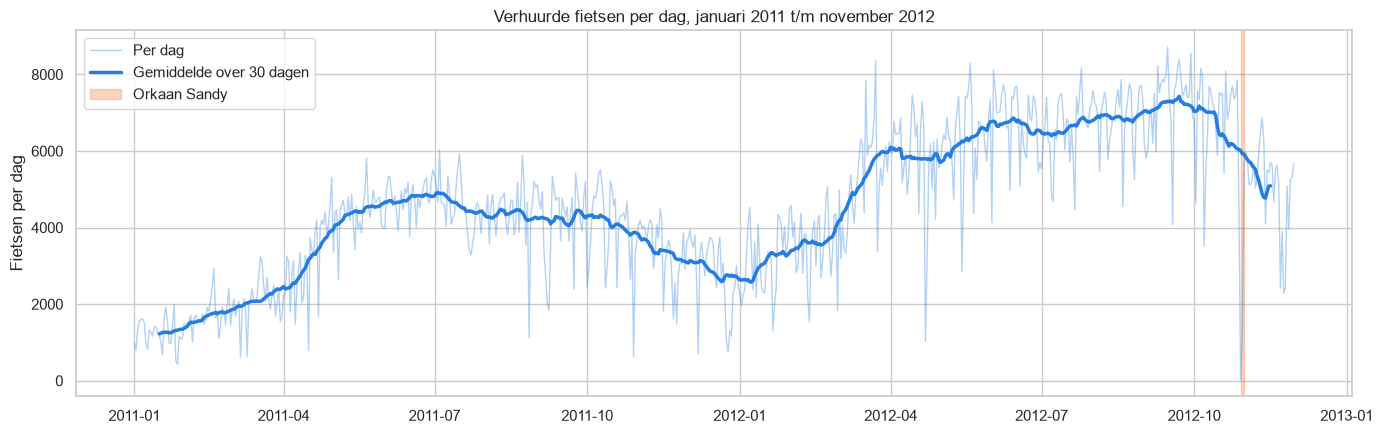

In [67]:
daily = train.groupby("date")[TARGET].sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily.index, daily.values, color=BLUE, alpha=0.35, linewidth=1,
        label="Per dag")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=BLUE,
        linewidth=2.5, label="Gemiddelde over 30 dagen")
# Orkaan Sandy markeren
ax.axvspan(pd.Timestamp("2012-10-29"), pd.Timestamp("2012-10-31"),
           color=ORANGE, alpha=0.3, label="Orkaan Sandy")
ax.set_title("Verhuurde fietsen per dag, januari 2011 t/m november 2012")
ax.set_ylabel("Fietsen per dag")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

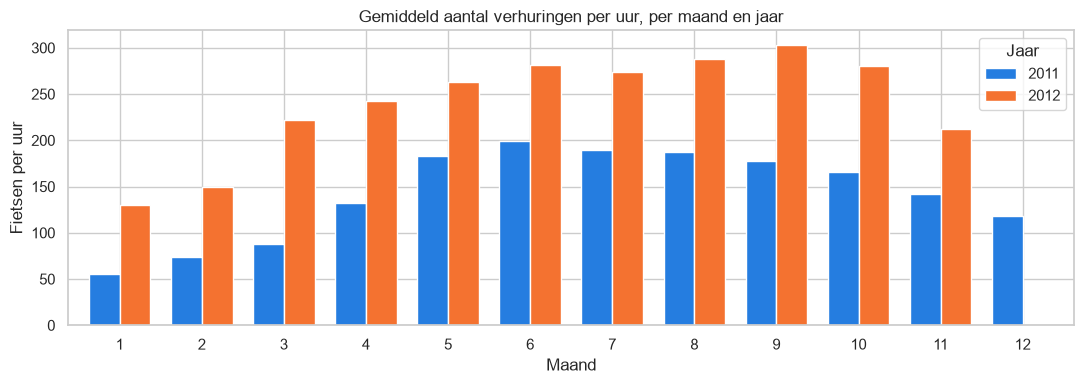

year,2011,2012,groei
month,,,
1,55.51,130.56,2.35
2,74.29,149.04,2.01
3,87.73,221.90,2.53
4,131.95,242.65,1.84
5,182.56,263.26,1.44
6,199.32,281.71,1.41
7,189.97,273.67,1.44
8,186.99,288.31,1.54
9,177.71,303.57,1.71


In [68]:
monthly = train.pivot_table(index="month", columns="year", values=TARGET,
                            aggfunc="mean")
monthly["groei"] = monthly[2012] / monthly[2011]

fig, ax = plt.subplots(figsize=(11, 4))
monthly[[2011, 2012]].plot(kind="bar", ax=ax, color=[BLUE, ORANGE],
                           width=0.75)
ax.set_title("Gemiddeld aantal verhuringen per uur, per maand en jaar")
ax.set_xlabel("Maand")
ax.set_ylabel("Fietsen per uur")
ax.legend(title="Jaar")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

monthly.round(2)

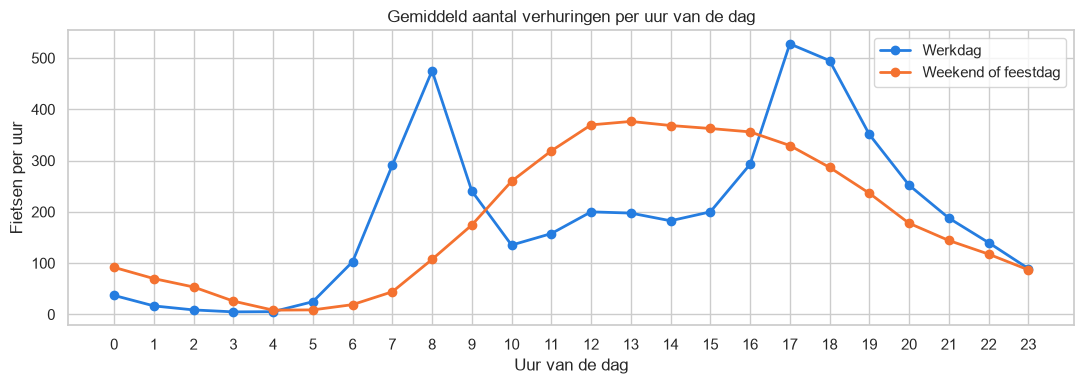

Drukste uren op een werkdag:
hour
17    528.0
18    495.0
8     475.0
Name: 1, dtype: float64


In [69]:
hourly = train.pivot_table(index="hour", columns="workingday",
                           values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly.index, hourly[1], color=BLUE, linewidth=2, marker="o",
        label="Werkdag")
ax.plot(hourly.index, hourly[0], color=ORANGE, linewidth=2, marker="o",
        label="Weekend of feestdag")
ax.set_title("Gemiddeld aantal verhuringen per uur van de dag")
ax.set_xlabel("Uur van de dag")
ax.set_ylabel("Fietsen per uur")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.show()

print("Drukste uren op een werkdag:")
print(hourly[1].sort_values(ascending=False).head(3).round(0))

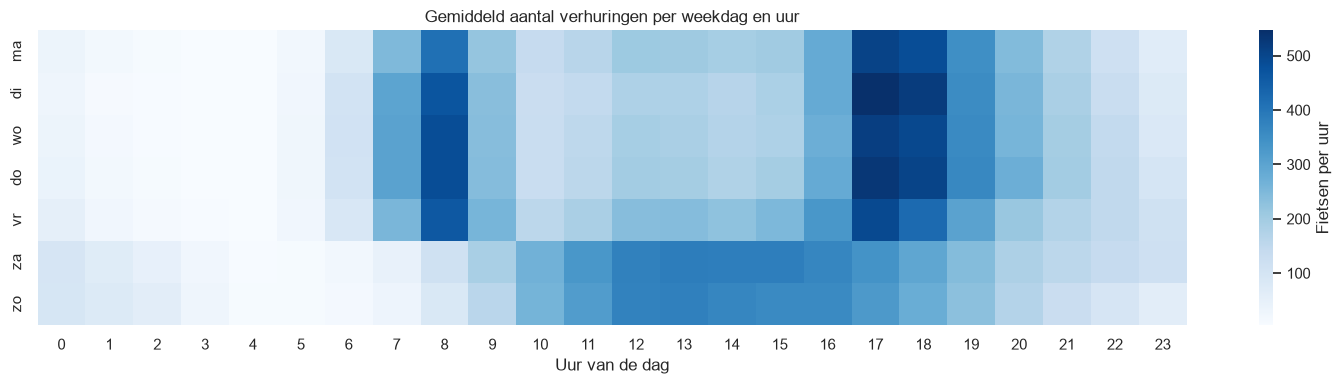

ma    184.7
di    191.0
wo    191.8
do    197.2
vr    196.8
za    191.8
zo    180.0
Name: cnt, dtype: float64

In [70]:
heat = train.pivot_table(index="weekday", columns="hour", values=TARGET,
                         aggfunc="mean")
heat.index = DAY_NAMES

plt.figure(figsize=(15, 4))
sns.heatmap(heat, cmap="Blues", cbar_kws={"label": "Fietsen per uur"})
plt.title("Gemiddeld aantal verhuringen per weekdag en uur")
plt.xlabel("Uur van de dag")
plt.ylabel("")
plt.tight_layout()
plt.show()

train.groupby("weekday")[TARGET].mean().set_axis(DAY_NAMES).round(1)

In [71]:
def mean_per_day(daily_counts, start, end):
    """Gemiddeld aantal verhuringen per dag tussen start en end."""
    return daily_counts[start:end].mean()


nov_2011 = mean_per_day(daily, "2011-11-01", "2011-11-30")
dec_2011 = mean_per_day(daily, "2011-12-01", "2011-12-19")
nov_2012 = mean_per_day(daily, "2012-11-01", "2012-11-30")
ratio = dec_2011 / nov_2011

print(f"November 2011:            {nov_2011:7.0f} per dag")
print(f"1 t/m 19 december 2011:   {dec_2011:7.0f} per dag "
      f"({ratio:.0%} van november)")
print(f"November 2012:            {nov_2012:7.0f} per dag")
print(f"Verwachting dec 2012:     {nov_2012 * ratio:7.0f} per dag, "
      f"ongeveer {nov_2012 * ratio / 24:.0f} per uur")

November 2011:               3406 per dag
1 t/m 19 december 2011:      3220 per dag (95% van november)
November 2012:               5089 per dag
Verwachting dec 2012:        4812 per dag, ongeveer 200 per uur


**Wat zien we?**

* **Er is een duidelijke groei.** In de eerste grafiek staan de verhuringen per dag, met een gemiddelde over 30 dagen erdoorheen. In 2012 worden per uur gemiddeld 241 fietsen verhuurd, tegen 144 in 2011. Dat is 68% meer. Als we per maand vergelijken, valt op dat de groei het grootst is in de wintermaanden aan het begin van het jaar. Maart 2012 is bijvoorbeeld 2,5 keer zo druk als maart 2011, terwijl de zomer van 2012 "maar" 1,4 keer zo druk is. Dit is de **trend** in de reeks.
* **Er is een seizoenspatroon per jaar.** In beide jaren is het druk van mei tot en met oktober en rustig in de winter. Januari is de rustigste maand. Het seizoen en de trend werken wel op elkaar in: de zomer van 2012 ligt veel hoger dan die van 2011.
* **Werkdagen en weekenden hebben een totaal ander dagpatroon.** Op werkdagen zijn er twee pieken: rond 8:00 (op weg naar het werk) en rond 17:00 en 18:00 (op weg naar huis). Op die momenten worden gemiddeld meer dan 450 fietsen per uur verhuurd. In het weekend en op feestdagen is er juist één brede bult tussen 11:00 en 17:00. Dat is recreatief gebruik. Een model moet dus niet alleen het uur kennen, maar ook weten of het een werkdag is.
* **Weekdagen lijken op elkaar.** De heatmap laat zien dat maandag tot en met vrijdag vrijwel hetzelfde patroon hebben, en dat zaterdag en zondag bij elkaar horen. Een indeling in werkdag en weekend vangt dus het grootste deel van het weekpatroon.
* **December is iets rustiger dan november.** De testperiode (1 t/m 19 december 2012) hebben we in 2012 nog niet gezien, wel in 2011. Toen lag 1 t/m 19 december op ongeveer 95% van november. Als dat in 2012 ook zo is, verwachten we in de testperiode ongeveer 4.800 verhuringen per dag, oftewel zo'n 200 per uur. Dit gebruiken we later als controle. Komen de voorspellingen van een model daar ver boven of onder, dan is er waarschijnlijk iets mis.

### 2.5 Relaties tussen de variabelen en cnt

In deze paragraaf onderzoeken we het verband tussen de onafhankelijke variabelen en `cnt`. Eerst kijken we naar de weerkolommen. Daarbij delen we de waarden op in groepen (bins) en tekenen we het gemiddelde per groep. Een scatterplot met 16.637 punten is namelijk niet goed te lezen. Het weer rekenen we daarbij terug naar echte eenheden (zie 2.2). Daarna kijken we of het effect van temperatuur verschilt per uur van de dag, en wat het weertype en feestdagen doen. Tot slot berekenen we welke kolommen het sterkst met `cnt` samenhangen.

Daarvoor gebruiken we twee soorten correlatie. Pearson meet alleen een rechtlijnig verband. Spearman kijkt naar de rangorde en vangt dus ook verbanden die wel stijgen of dalen, maar niet in een rechte lijn. Als Spearman veel hoger is dan Pearson, weten we dus dat een verband niet rechtlijnig is.

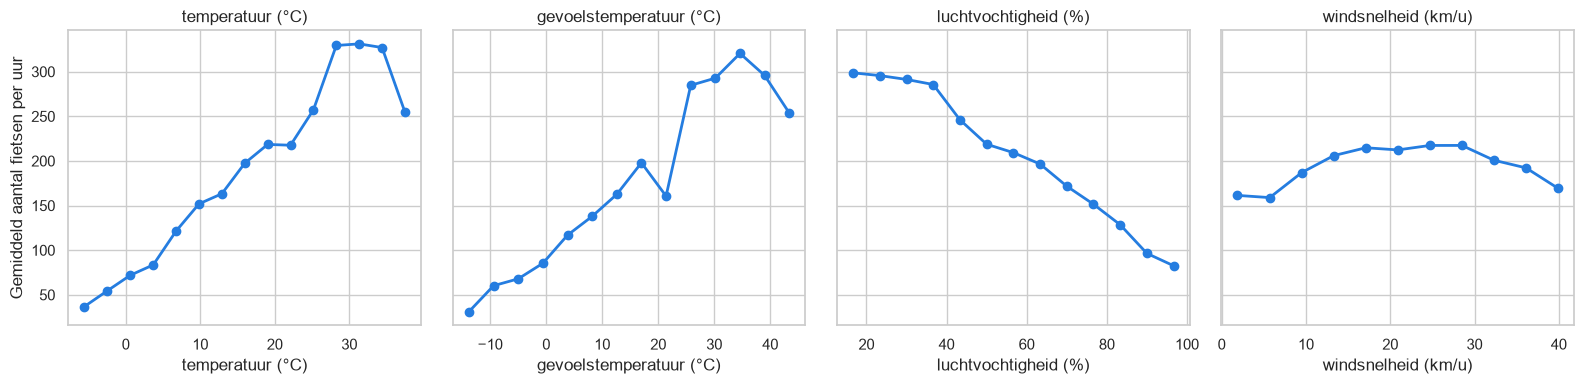

In [72]:
def to_real_units(df):
    """Rekent de genormaliseerde weerkolommen terug naar echte eenheden."""
    return pd.DataFrame({
        "temperatuur (°C)": df["temp"] * 47 - 8,
        "gevoelstemperatuur (°C)": df["atemp"] * 66 - 16,
        "luchtvochtigheid (%)": df["hum"] * 100,
        "windsnelheid (km/u)": df["windspeed"] * 67,
    })


def plot_binned_mean(df, columns, target, bins=15):
    """Gemiddelde target per bin voor iedere continue kolom."""
    fig, axes = plt.subplots(1, len(columns), figsize=(16, 4), sharey=True)
    for ax, col in zip(axes, columns):
        groups = pd.cut(df[col], bins=bins)
        means = df.groupby(groups, observed=True)[target].agg(
            ["mean", "size"])
        # Bins met heel weinig uren zijn onbetrouwbaar, die laten we weg
        means = means[means["size"] >= 30]
        centers = [interval.mid for interval in means.index]
        ax.plot(centers, means["mean"], color=BLUE, marker="o",
                linewidth=2)
        ax.set_title(col)
        ax.set_xlabel(col)
    axes[0].set_ylabel("Gemiddeld aantal fietsen per uur")
    plt.tight_layout()
    plt.show()


weather_real = to_real_units(train)
weather_real[TARGET] = train[TARGET]
plot_binned_mean(weather_real, weather_real.columns[:-1], TARGET)

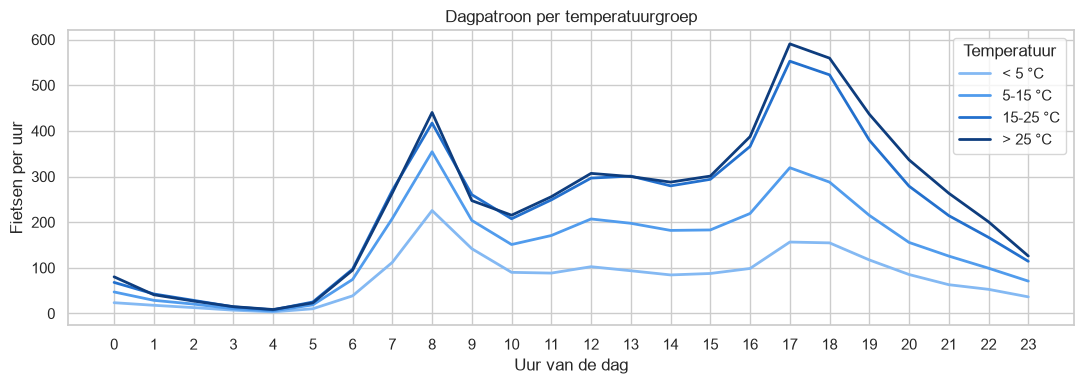

In [73]:
temp_groups = pd.cut(weather_real["temperatuur (°C)"],
                     bins=[-10, 5, 15, 25, 40],
                     labels=["< 5 °C", "5-15 °C", "15-25 °C", "> 25 °C"])
temp_hour = train.groupby([temp_groups, "hour"],
                          observed=True)[TARGET].mean().unstack(0)

fig, ax = plt.subplots(figsize=(11, 4))
# Licht naar donker blauw: hoe donkerder, hoe warmer
temp_hour.plot(ax=ax, linewidth=2,
               color=["#84b9f3", "#519ced", "#2370cd", "#0e3d7e"])
ax.set_title("Dagpatroon per temperatuurgroep")
ax.set_xlabel("Uur van de dag")
ax.set_ylabel("Fietsen per uur")
ax.set_xticks(range(24))
ax.legend(title="Temperatuur")
plt.tight_layout()
plt.show()

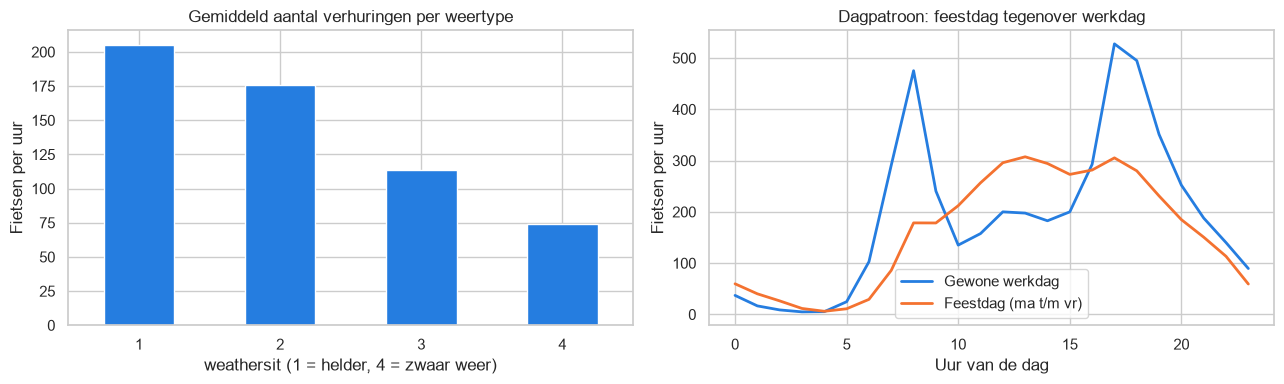

,mean,size
weathersit,,
1,205.4,11078
2,175.8,4207
3,113.5,1349
4,74.3,3


In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Weertype: gemiddelde en aantal uren
weather_stats = train.groupby("weathersit")[TARGET].agg(["mean", "size"])
weather_stats["mean"].plot(kind="bar", ax=axes[0], color=BLUE)
axes[0].set_title("Gemiddeld aantal verhuringen per weertype")
axes[0].set_xlabel("weathersit (1 = helder, 4 = zwaar weer)")
axes[0].set_ylabel("Fietsen per uur")
axes[0].tick_params(axis="x", rotation=0)

# Feestdag tegenover gewone werkdag, alleen maandag t/m vrijdag
weekdays_only = train[train["is_weekend"] == 0]
holiday_hour = weekdays_only.pivot_table(index="hour", columns="holiday",
                                         values=TARGET, aggfunc="mean")
axes[1].plot(holiday_hour.index, holiday_hour[0], color=BLUE, linewidth=2,
             label="Gewone werkdag")
axes[1].plot(holiday_hour.index, holiday_hour[1], color=ORANGE,
             linewidth=2, label="Feestdag (ma t/m vr)")
axes[1].set_title("Dagpatroon: feestdag tegenover werkdag")
axes[1].set_xlabel("Uur van de dag")
axes[1].set_ylabel("Fietsen per uur")
axes[1].legend()
plt.tight_layout()
plt.show()

weather_stats.round(1)

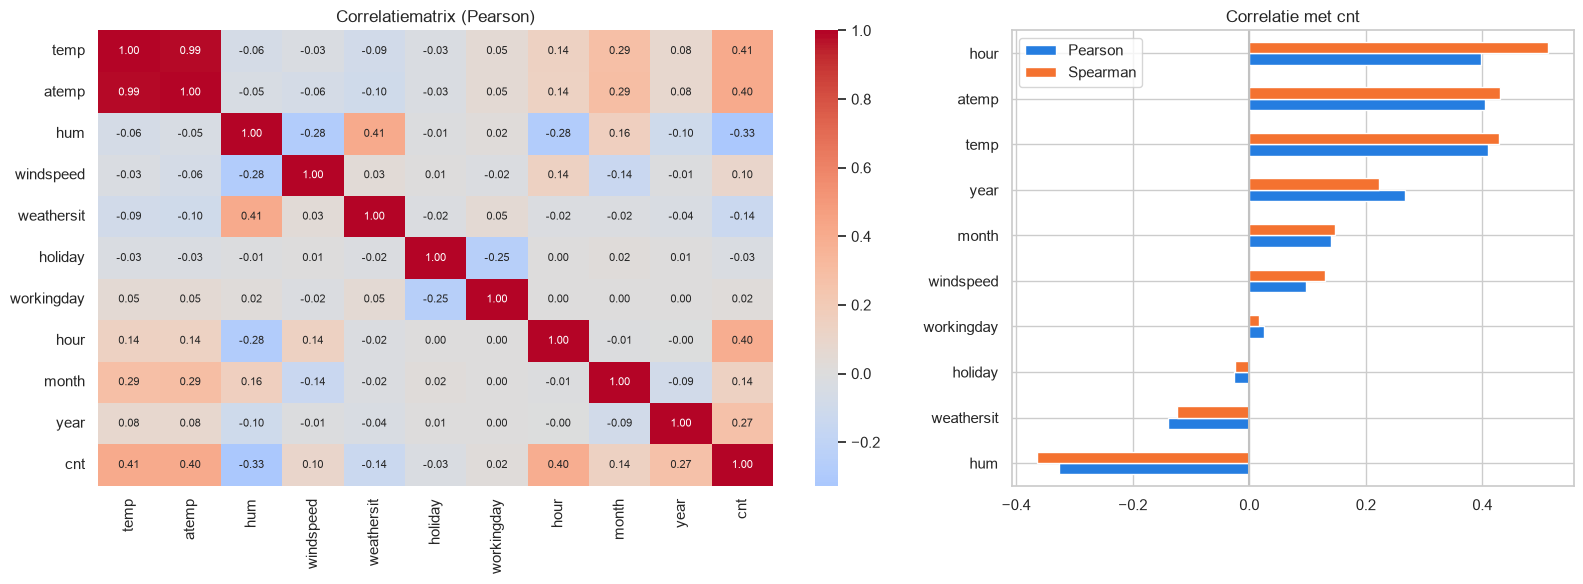

,Pearson,Spearman
hum,-0.327,-0.364
weathersit,-0.140,-0.124
holiday,-0.027,-0.024
workingday,0.025,0.016
windspeed,0.097,0.130
month,0.140,0.148
year,0.267,0.223
temp,0.409,0.429
atemp,0.405,0.430
hour,0.397,0.513


In [75]:
corr_cols = ["temp", "atemp", "hum", "windspeed", "weathersit", "holiday",
             "workingday", "hour", "month", "year", TARGET]

fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [3, 2]})
sns.heatmap(train[corr_cols].corr(), cmap="coolwarm", center=0, annot=True,
            fmt=".2f", annot_kws={"size": 8}, ax=axes[0])
axes[0].set_title("Correlatiematrix (Pearson)")

corr_target = pd.DataFrame({
    "Pearson": train[corr_cols].corr()[TARGET],
    "Spearman": train[corr_cols].corr(method="spearman")[TARGET],
}).drop(TARGET).sort_values("Spearman")
corr_target.plot(kind="barh", ax=axes[1], color=[BLUE, ORANGE])
axes[1].set_title("Correlatie met cnt")
axes[1].axvline(0, color="#c2c2c2")
plt.tight_layout()
plt.show()

corr_target.round(3)

### 2.6 Belangrijkste bevindingen

1. **Het tijdstip is de belangrijkste factor.** Het uur van de dag heeft de hoogste Spearman-correlatie met `cnt` (0,51). Op werkdagen zijn er twee spitspieken rond 8:00 en 17:00 tot 18:00, in het weekend één brede bult rond het middaguur. Het verband met `hour` is dus niet rechtlijnig, en dat zie je ook terug in de correlatie: Pearson (0,40) is lager dan Spearman. Een lineair model kan dit patroon alleen leren als we het uur slim omzetten, bijvoorbeeld met dummies of Fourier-termen (hoofdstuk 3).
2. **Werkdag of weekend bepaalt de vorm van de dag.** De correlatie van `workingday` met `cnt` is bijna 0. Eerst dachten we dat werkdag dus niet belangrijk was, maar dat klopt niet. Over een hele dag zijn de totalen namelijk ongeveer gelijk, alleen de verdeling over de uren is anders. Het effect zit dus in de combinatie met `hour`, oftewel een interactie. Boommodellen vinden zo'n combinatie zelf, een lineair model niet.
3. **Er is een sterke stijgende trend.** 2012 is gemiddeld 68% drukker dan 2011. Omdat we december 2012 voorspellen, moet een model deze trend kunnen doortrekken. En daar zit een probleem: boommodellen kunnen dat niet, omdat ze nooit hoger voorspellen dan wat ze in de training hebben gezien. Dat is een belangrijke reden voor een hybride model (4.9).
4. **Er is een seizoenspatroon per jaar.** Zomer is druk, winter rustig. Dit hangt sterk samen met de temperatuur, die van de weerkolommen de hoogste correlatie heeft (Pearson 0,41).
5. **Warm weer helpt, maar niet onbeperkt.** Het aantal verhuringen stijgt met de temperatuur tot ongeveer 30 °C, daarna daalt het weer. Wat ons opviel, is dat het effect per moment van de dag verschilt. In de ochtendspits maakt het weinig uit of het 10 of 25 °C is: wie naar zijn werk moet, fietst toch. In de avondspits en overdag is het verschil veel groter. Om 17:00 worden bij 5 tot 15 °C ongeveer 320 fietsen verhuurd, boven 25 °C zijn dat er ongeveer 590. De terugrit en het vrije tijdsgebruik hangen dus meer af van het weer. Dit is een interactie tussen `temp` en `hour`.
6. **Slecht weer en een hoge luchtvochtigheid verlagen de vraag.** Bij lichte regen of sneeuw (`weathersit` 3) worden gemiddeld 114 fietsen per uur verhuurd, tegen 205 bij helder weer. Een hoge luchtvochtigheid hangt vaak samen met regen en heeft een negatieve correlatie (−0,33). Windsnelheid maakt weinig uit.
7. **Feestdagen lijken op een weekenddag.** Op een feestdag doordeweeks verdwijnen de spitspieken. Dat bevestigt dat `workingday` een betere feature is dan alleen `holiday`. In de testperiode valt overigens geen feestdag.
8. **`temp` en `atemp` zeggen bijna hetzelfde** (correlatie 0,99). Als we ze allebei gebruiken, krijgen we bij lineaire regressie onstabiele coëfficiënten (multicollineariteit). Bij lineaire regressie houden we er daarom één over.
9. **De data heeft een paar eigenaardigheden.** Er ontbreken 163 uren, die waarschijnlijk 0 verhuringen betekenen. Daarnaast zijn er twee meetfouten (luchtvochtigheid op 10-3-2011 en gevoelstemperatuur op 17-8-2012) en één bijna lege categorie (`weathersit` 4). Die schonen we op in 2.7.
10. **December 2012 ligt naar verwachting rond 200 fietsen per uur.** Dat schatten we uit de verhouding tussen december en november in 2011. Dit is een handige controle voor onze voorspellingen.

### 2.7 Data opschonen

In [76]:
class BikeCleaner:
    """Schoont de fietsdata op en houdt bij welke stappen zijn gedaan."""

    def __init__(self, df):
        # Kopie, zodat de originele data onveranderd blijft
        self.df = df.copy().sort_values("date_hour").reset_index(drop=True)
        self.log = []

    def _add_log(self, step, rows):
        """Slaat een stap op met het aantal aangepaste rijen."""
        self.log.append({"stap": step, "rijen aangepast": int(rows)})

    def fix_wrong_values(self, column, mask, reason):
        """Vervangt foute waarden door interpolatie in de tijd."""
        self._add_log(reason, mask.sum())
        self.df.loc[mask, column] = np.nan
        self.df[column] = self.df[column].interpolate(method="linear")
        return self

    def merge_weather_4(self):
        """Voegt weertype 4 (3 uren) samen met weertype 3."""
        mask = self.df["weathersit"] == 4
        self._add_log("weathersit 4 samengevoegd met 3", mask.sum())
        self.df.loc[mask, "weathersit"] = 3
        return self

    def fill_missing_hours(self):
        """Vult ontbrekende uren aan met cnt = 0 en het weer van het uur
        ervoor. Alleen voor de trainingsdata, want test heeft geen gaten."""
        full = pd.date_range(self.df["date_hour"].min(),
                             self.df["date_hour"].max(), freq="h")
        n_missing = len(full) - len(self.df)
        self.df = (self.df.set_index("date_hour").reindex(full)
                   .rename_axis("date_hour").reset_index())
        if TARGET in self.df.columns:
            self.df[TARGET] = self.df[TARGET].fillna(0).astype(int)
        weather = ["holiday", "weathersit"] + WEATHER_COLS
        self.df[weather] = self.df[weather].ffill()
        self.df["weathersit"] = self.df["weathersit"].astype(int)
        self.df["holiday"] = self.df["holiday"].astype(int)
        self._add_log("ontbrekende uren toegevoegd (cnt = 0)", n_missing)
        return self

    def summary(self):
        """Overzicht van alle opschoonstappen."""
        return pd.DataFrame(self.log)


def clean(df, fill_hours=True):
    """Voert alle opschoonstappen uit op train of test."""
    cleaner = BikeCleaner(df)
    temp_c = cleaner.df["temp"] * 47 - 8
    atemp_c = cleaner.df["atemp"] * 66 - 16
    wrong_atemp = ((cleaner.df["date_hour"].dt.date
                    == pd.Timestamp("2012-08-17").date())
                   & ((temp_c - atemp_c).abs() > 10))
    cleaner.fix_wrong_values("hum", cleaner.df["hum"] == 0,
                             "hum = 0 geïnterpoleerd (meetfout)")
    cleaner.fix_wrong_values("atemp", wrong_atemp,
                             "atemp 17-8-2012 geïnterpoleerd (meetfout)")
    cleaner.merge_weather_4()
    # Pas na het herstellen van de meetfouten de gaten opvullen, anders
    # worden foute waarden doorgekopieerd naar de nieuwe uren
    if fill_hours:
        cleaner.fill_missing_hours()
    return cleaner


train_cleaner = clean(data.train)
test_cleaner = clean(data.test, fill_hours=False)
train_clean = add_time_elements(train_cleaner.df)
test_clean = add_time_elements(test_cleaner.df)

print(f"train: {data.train.shape} -> {train_clean.shape}")
print(f"test:  {data.test.shape} -> {test_clean.shape}")
train_cleaner.summary()

train: (16637, 8) -> (16800, 15)
test:  (456, 7) -> (456, 14)


,stap,rijen aangepast
0,hum = 0 geïnterpoleerd (meetfout),22
1,atemp 17-8-2012 geïnterpoleerd (meetfout),24
2,weathersit 4 samengevoegd met 3,3
3,ontbrekende uren toegevoegd (cnt = 0),163


**Waarom deze keuzes**

1. **163 ontbrekende uren toegevoegd met `cnt` = 0.** In de EDA zagen we dat `cnt` nooit 0 is en dat de gaten vooral 's nachts vallen. Een uur zonder verhuring staat dus niet in de data. Voor tijdreeksmodellen als SARIMA(X) is een reeks zonder gaten verplicht, omdat het model ervan uitgaat dat iedere stap precies één uur is. Ook features als "hetzelfde uur een week eerder" (hoofdstuk 3) kloppen alleen als ieder uur aanwezig is. Het weer van zo'n uur nemen we over van het uur ervoor (forward fill). Het weer verandert binnen een uur immers meestal niet veel.
2. **Luchtvochtigheid van 0% geïnterpoleerd (22 uren).** Een luchtvochtigheid van 0% kan niet, en komt alleen op 10 maart 2011 voor. We vervangen deze waarden door lineaire interpolatie. Dat betekent dat we een rechte lijn trekken tussen de laatste goede meting ervoor en de eerste goede meting erna.
3. **Gevoelstemperatuur op 17 augustus 2012 geïnterpoleerd.** De hele dag ligt `atemp` meer dan 10 °C onder `temp`, en dat op een warme zomerdag. Ook dit is dus een meetfout.
4. **`weathersit` 4 samengevoegd met 3.** Drie uren zijn te weinig om iets van te leren. Bovendien betekenen weertype 3 en 4 allebei neerslag. In de testset komt 4 niet voor.
5. **Wat we niet doen.** We verwijderen geen drukke uren (outliers), want dat zijn juist de spitsuren die we willen voorspellen. Ook de dagen rond orkaan Sandy laten we staan. De waarde 0 klopt daar namelijk echt: het systeem was dicht. In de testset halen we geen rijen weg, omdat Kaggle voor ieder uur een voorspelling wil.

## 3. Time series feature engineering

### 3.1 Seizoenspatronen (Fourier analyse)

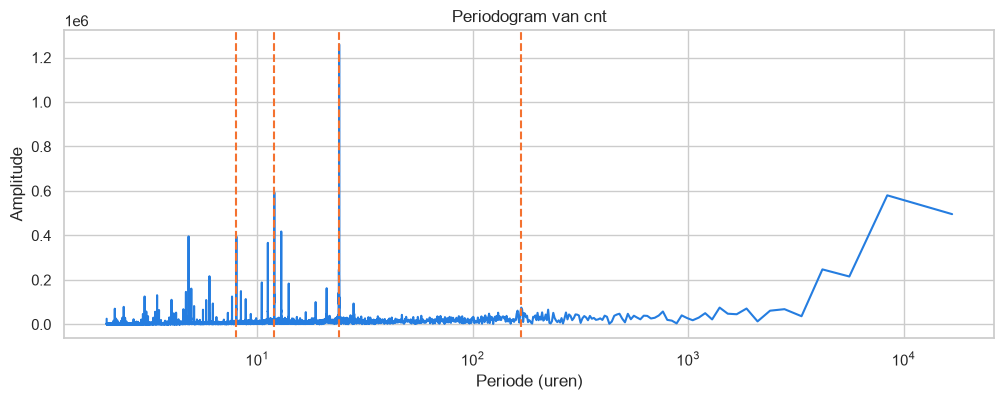

In [77]:
# Periodogram: welke periodes zitten er in cnt?
waarden = train_clean[TARGET] - train_clean[TARGET].mean()
amplitude = np.abs(np.fft.rfft(waarden))[1:]
periode = 1 / np.fft.rfftfreq(len(waarden))[1:]

plt.figure(figsize=(12, 4))
plt.plot(periode, amplitude, color=BLUE)
for p in [8, 12, 24, 168]:
    plt.axvline(p, color=ORANGE, linestyle="--")
plt.xscale("log")
plt.xlabel("Periode (uren)")
plt.ylabel("Amplitude")
plt.title("Periodogram van cnt")
plt.show()

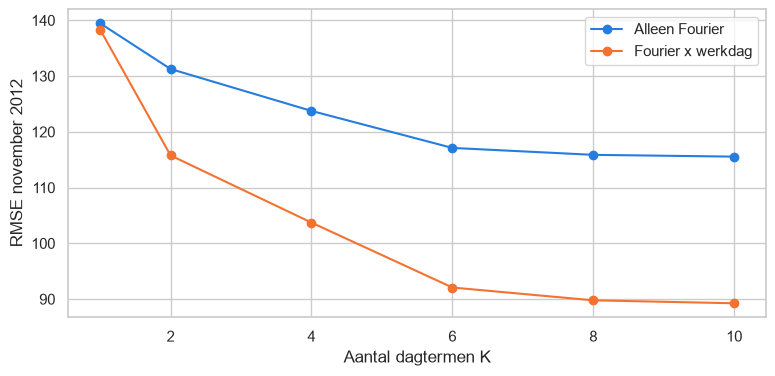

In [78]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

START = train_clean["date_hour"].min()


def fourier(df, k_dag=6, k_week=2, k_jaar=2):
    # t = aantal uren sinds 1 jan 2011, werkt dus ook voor de testset
    t = (df["date_hour"] - START) / pd.Timedelta(hours=1)
    X = pd.DataFrame(index=df.index)
    for naam, P, K in [("dag", 24, k_dag), ("week", 168, k_week),
                       ("jaar", 8766, k_jaar)]:
        for k in range(1, K + 1):
            X[f"sin_{naam}_{k}"] = np.sin(2 * np.pi * k * t / P)
            X[f"cos_{naam}_{k}"] = np.cos(2 * np.pi * k * t / P)
    return X


def met_werkdag(df, X):
    # Dagtermen keer workingday, zodat werkdagen een eigen dagvorm krijgen
    dag = X.filter(like="_dag_").mul(df["workingday"], axis=0)
    return X.join(dag.add_prefix("werkdag_"))


val = train_clean["date_hour"] >= "2012-11-01"   # november 2012 als validatie
y = train_clean[TARGET]


def score(X):
    model = LinearRegression().fit(X[~val], y[~val])
    return root_mean_squared_error(y[val], model.predict(X[val]))


ks = [1, 2, 4, 6, 8, 10]
zonder, met = [], []
for k in ks:
    X = fourier(train_clean, k_dag=k)
    X["t"] = (train_clean["date_hour"] - START) / pd.Timedelta(hours=1)
    zonder.append(score(X))
    met.append(score(met_werkdag(train_clean, X)))

plt.figure(figsize=(9, 4))
plt.plot(ks, zonder, marker="o", color=BLUE, label="Alleen Fourier")
plt.plot(ks, met, marker="o", color=ORANGE, label="Fourier x werkdag")
plt.xlabel("Aantal dagtermen K")
plt.ylabel("RMSE november 2012")
plt.legend()
plt.show()

**Wat zien we?**

Het periodogram laat de sterkste piek zien bij 24 uur, het dagpatroon. De pieken bij 12 en 8 uur horen daar ook bij: één golf van 24 uur heeft maar één top, terwijl een werkdag er twee heeft (ochtend- en avondspits). Daarnaast is er een kleinere piek bij 168 uur, de week.

Daarom maken we Fourier-features: voor dag, week en jaar een aantal sinussen en cosinussen van $\frac{2\pi k t}{P}$, met $t$ het aantal uren sinds 1 januari 2011. Deze kunnen we ook voor december 2012 uitrekenen. Na ongeveer $K$ = **[ ]** dagtermen daalt de RMSE bijna niet meer, dus meer termen heeft geen zin. De grootste verbetering komt van de combinatie met `workingday`, omdat werkdagen een heel andere dagvorm hebben dan weekenden (zie 2.4). De RMSE gaat daardoor van **[ ]** naar **[ ]**.

**Keuze:** $K$ = **[ ]** voor de dag, 2 voor de week en 2 voor het jaar, plus de interactie met werkdag.

### 3.2 Trends

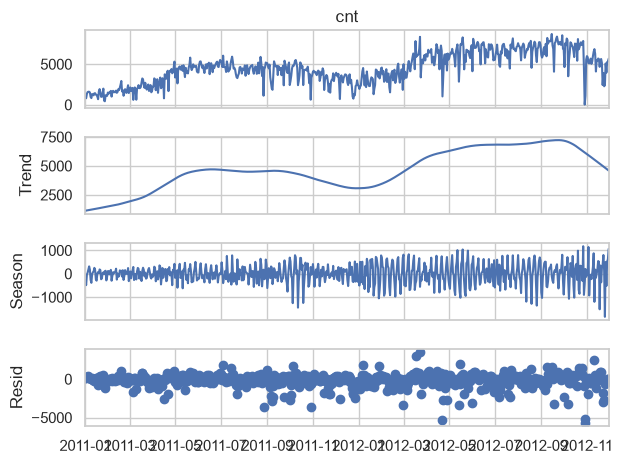

In [79]:
from statsmodels.tsa.seasonal import STL

per_dag = train_clean.groupby("date")[TARGET].sum().asfreq("D")
STL(per_dag, period=7, trend=91, robust=True).fit().plot()
plt.show()

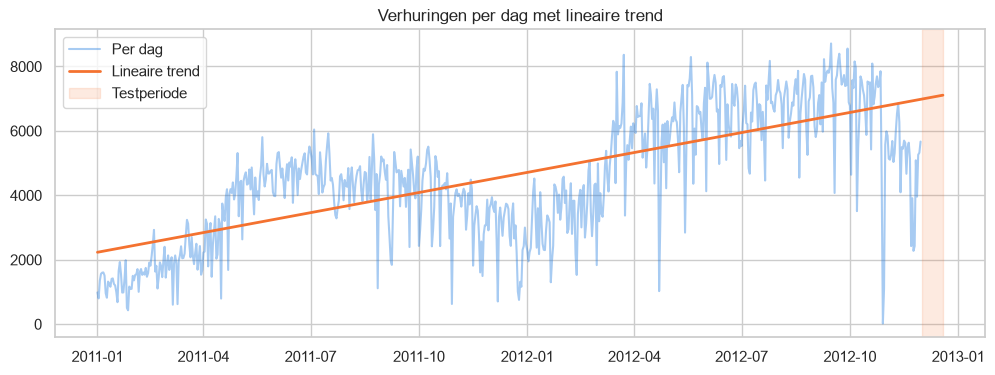

Groei: 6.8 fietsen per dag erbij, elke dag


In [80]:
# Lineaire trend op de dagtotalen (jan t/m nov, zodat beide jaren even
# veel winter hebben), doorgetrokken naar december 2012
jan_nov = per_dag[per_dag.index.month <= 11]
dagnr = (jan_nov.index - per_dag.index[0]).days
a, b = np.polyfit(dagnr, jan_nov, 1)

alle_dagen = np.arange(len(per_dag) + 19)
datums = pd.date_range(per_dag.index[0], periods=len(alle_dagen))

plt.figure(figsize=(12, 4))
plt.plot(per_dag.index, per_dag, color=BLUE, alpha=0.4, label="Per dag")
plt.plot(datums, a * alle_dagen + b, color=ORANGE, linewidth=2,
         label="Lineaire trend")
plt.axvspan(datums[-19], datums[-1], color=ORANGE, alpha=0.15,
            label="Testperiode")
plt.legend()
plt.title("Verhuringen per dag met lineaire trend")
plt.show()

print(f"Groei: {a:.1f} fietsen per dag erbij, elke dag")

In [81]:
# Welke trendfeature werkt het best?
X = met_werkdag(train_clean, fourier(train_clean, k_dag=8))
t = (train_clean["date_hour"] - START) / pd.Timedelta(hours=1)
jaar = (train_clean["year"] == 2012).astype(int)

print("geen trend:   ", round(score(X), 1))
print("jaar 2012:    ", round(score(X.assign(jaar=jaar)), 1))
print("t (lineair):  ", round(score(X.assign(t=t)), 1))
print("t + jaar 2012:", round(score(X.assign(t=t, jaar=jaar)), 1))

geen trend:    96.9
jaar 2012:     86.5
t (lineair):   89.8
t + jaar 2012: 88.6


**Wat zien we?**

De STL-decompositie laat een duidelijke stijgende trend zien: 2012 ligt een stuk hoger dan 2011, met daaroverheen het seizoen. Het weekpatroon is klein, omdat werkdagen en weekenden per dag ongeveer even druk zijn. Volgens de lineaire trend komen er elke dag ongeveer **[ ]** verhuringen bij.

Een boommodel kan deze groei niet doortrekken naar december, omdat het nooit hoger voorspelt dan wat het in de training heeft gezien. Een lineair model kan dat wel. Daarom maken we in 4.9 een hybride model. Met `t` als feature daalt de RMSE van **[ ]** naar **[ ]**.

**Keuze:** we nemen `t` mee als trendfeature.

### 3.3 Cycli en autocorrelatie

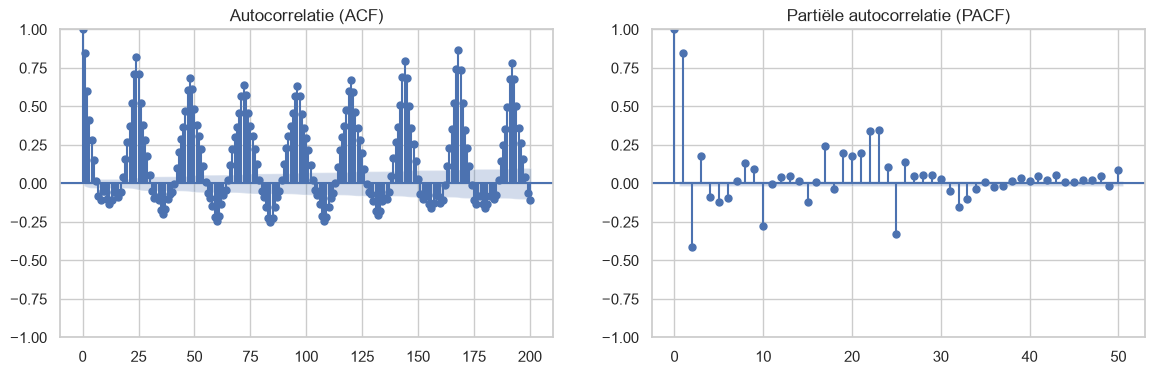

1 uur    0.846
1 dag    0.820
1 week   0.874
3 weken  0.869
4 weken  0.860


In [82]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train_clean[TARGET], lags=200, ax=axes[0])
plot_pacf(train_clean[TARGET], lags=50, ax=axes[1], method="ywm")
axes[0].set_title("Autocorrelatie (ACF)")
axes[1].set_title("Partiële autocorrelatie (PACF)")
plt.show()

# Hoe sterk hangt cnt samen met cnt van een tijd geleden?
for lag, naam in [(1, "1 uur"), (24, "1 dag"), (168, "1 week"),
                  (504, "3 weken"), (672, "4 weken")]:
    r = train_clean[TARGET].corr(train_clean[TARGET].shift(lag))
    print(f"{naam:<8} {r:.3f}")

In [83]:
# Train en test aan elkaar plakken, zodat de lags voor december
# gewoon uit november komen. We voorspellen 19 dagen vooruit, dus
# alleen lags van minstens 19 * 24 = 456 uur kunnen we gebruiken.
alles = (pd.concat([train_clean, test_clean])
         .sort_values("date_hour").reset_index(drop=True))

alles["lag_3w"] = alles[TARGET].shift(504)                    # zelfde uur, 3 weken terug
alles["gem_3w"] = alles[TARGET].shift(504).rolling(168).mean()  # weekgemiddelde, 3 weken terug

print(alles.loc[alles["date_hour"] >= "2012-12-01",
                ["date_hour", "lag_3w", "gem_3w"]].head())

                date_hour  lag_3w      gem_3w
16800 2012-12-01 00:00:00   122.0  223.488095
16801 2012-12-01 01:00:00    76.0  223.410714
16802 2012-12-01 02:00:00    44.0  223.398810
16803 2012-12-01 03:00:00    20.0  223.351190
16804 2012-12-01 04:00:00     6.0  223.291667


**Wat zien we?**

De ACF laat duidelijke pieken zien om de 24 uur en een extra hoge piek bij 168 uur: het aantal verhuringen lijkt sterk op dat van hetzelfde uur een dag en een week eerder. De PACF laat zien dat vooral de laatste paar uren en lag 24 direct iets toevoegen.

Het probleem is dat we 19 dagen vooruit voorspellen. Voor december weten we `cnt` van een uur of een dag eerder niet. Alleen lags van minstens 456 uur kunnen we gebruiken. Daarom nemen we hetzelfde uur 3 weken eerder (`lag_3w`) en het weekgemiddelde van 3 weken eerder (`gem_3w`). De correlatie van lag 3 weken met `cnt` is **[ ]**, dus nog steeds behoorlijk hoog.

### 3.4 Andere tijdsgebaseerde features

In [84]:
def extra_features(df):
    df = df.copy()
    df["spits"] = (df["workingday"].eq(1)
                   & df["hour"].isin([7, 8, 17, 18, 19])).astype(int)
    df["nacht"] = df["hour"].between(0, 5).astype(int)
    df["slecht_weer"] = (df["weathersit"] >= 3).astype(int)
    df["temp_kwadraat"] = df["temp"] ** 2      # warm helpt, té warm niet
    return df


alles = extra_features(alles)
train_deel = alles[alles["date_hour"] < "2012-12-01"]

print(train_deel.groupby("spits")[TARGET].mean().round(0))
print(train_deel.groupby("slecht_weer")[TARGET].mean().round(0))

spits
0    149.0
1    426.0
Name: cnt, dtype: float64
slecht_weer
0    197.0
1    105.0
Name: cnt, dtype: float64


**Wat zien we?**

We hebben een paar features toegevoegd op basis van de EDA. `spits` geeft aan of het een spitsuur op een werkdag is, `nacht` de uren tussen 0:00 en 5:00, en `slecht_weer` of het regent of sneeuwt. Spitsuren hebben gemiddeld **[ ]** verhuringen tegenover **[ ]** voor andere uren, en bij slecht weer zakt het gemiddelde naar **[ ]**. Omdat heel warm weer weer minder fietsers geeft (zie 2.5), voegen we ook `temp_kwadraat` toe. Dan kan een lineair model ook een bocht leren in plaats van alleen een rechte lijn.

### 3.5 Invloed van de features en uiteindelijke keuze

In [85]:
from sklearn.ensemble import RandomForestRegressor

X_alles = met_werkdag(alles, fourier(alles, k_dag=8))
fourier_cols = list(X_alles.columns)
X_alles["t"] = (alles["date_hour"] - START) / pd.Timedelta(hours=1)

basis = ["hour", "weekday", "workingday", "holiday", "weathersit",
         "temp", "atemp", "hum", "windspeed"]
lags = ["lag_3w", "gem_3w"]
extra = ["spits", "nacht", "slecht_weer", "temp_kwadraat"]
X_alles = X_alles.join(alles[basis + lags + extra])

# Train = t/m november (zonder de eerste weken, daar zijn de lags leeg)
is_train = (alles["date_hour"] < "2012-12-01") & alles["gem_3w"].notna()
X_tr, y_tr = X_alles[is_train], alles.loc[is_train, TARGET]
X_test = X_alles[alles["date_hour"] >= "2012-12-01"]
val = alles.loc[is_train, "date_hour"] >= "2012-11-01"

groepen = {
    "weer + kalender": basis,
    "+ Fourier": basis + fourier_cols,
    "+ trend": basis + fourier_cols + ["t"],
    "+ lags": basis + fourier_cols + ["t"] + lags,
    "+ extra": basis + fourier_cols + ["t"] + lags + extra,
}

rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3,
                           n_jobs=-1, random_state=42)
uitslag = []
for naam, cols in groepen.items():
    rij = {"features": naam}
    for model_naam, model in [("Lineair", LinearRegression()), ("Random forest", rf)]:
        model.fit(X_tr.loc[~val, cols], y_tr[~val])
        pred = model.predict(X_tr.loc[val, cols])
        rij[model_naam] = root_mean_squared_error(y_tr[val], pred)
    uitslag.append(rij)

pd.DataFrame(uitslag).round(1)

,features,Lineair,Random forest
0,weer + kalender,169.4,107.9
1,+ Fourier,90.2,108.1
2,+ trend,84.5,92.7
3,+ lags,91.5,85.4
4,+ extra,91.2,84.5


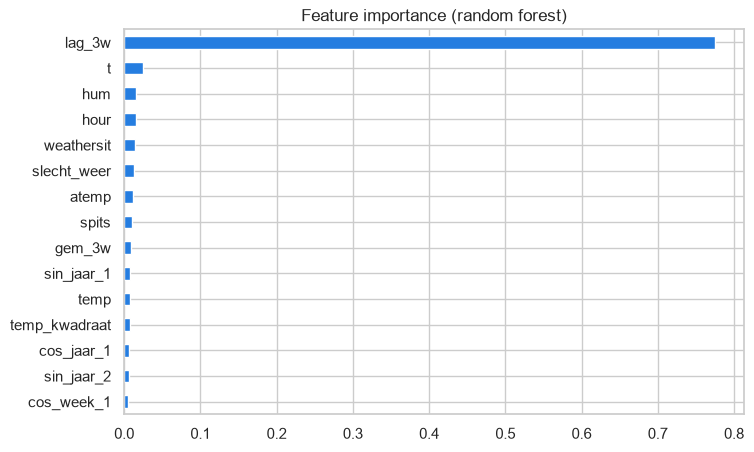

In [86]:
# Welke features gebruikt het random forest het meest? (laatste fit = alle features)
belang = pd.Series(rf.feature_importances_, index=groepen["+ extra"])
belang.sort_values().tail(15).plot(kind="barh", color=BLUE, figsize=(8, 5))
plt.title("Feature importance (random forest)")
plt.show()

**Wat zien we?**

We hebben de features stap voor stap toegevoegd en steeds de RMSE op november 2012 bekeken. Bij het lineaire model geven vooral de Fourier-termen een grote verbetering (van **[ ]** naar **[ ]**), omdat het model het dagpatroon anders niet kan leren. Het random forest heeft daar minder aan, want dat leert het patroon al uit `hour` en `workingday`. De lags en extra features helpen allebei nog **[een beetje / niet veel]**.

Volgens de feature importance van het random forest zijn **[ ]**, **[ ]** en **[ ]** het belangrijkst. Dat past bij de EDA: het tijdstip en het soort dag bepalen het meest, daarna komt het weer.

**Keuze:** we gaan verder met alle features. Voor het lineaire model zijn de Fourier-termen en `t` het belangrijkst, voor de boommodellen de gewone kalender- en weerfeatures.

## 4. Modelleren

### 4.1 Aanpak: RMSE, cross-validation en hyperparameter tuning

**RMSE.** Kaggle beoordeelt de voorspellingen met de Root Mean Squared Error:

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

Hierin is $y_i$ het echte aantal fietsen en $\hat{y}_i$ de voorspelling. De RMSE is uitgedrukt in fietsen per uur. Door het kwadraat tellen grote fouten zwaarder mee dan kleine. Wij moeten op Kaggle onder de 80 uitkomen.

**Cross-validation voor tijdreeksen.** Bij gewone k-fold cross-validation worden de rijen gehusseld. Het model traint dan op uren die ná de testuren liggen en kijkt dus in de toekomst. Daarom gebruiken we `TimeSeriesSplit`: het model traint altijd op het verleden en wordt getest op de periode direct daarna. Iedere testfold is **19 dagen**, net zo lang als de Kaggle-testperiode (1 t/m 19 december). Zo kan de lag van 3 weken (504 uur) nooit naar een uur in de testfold wijzen, net als bij Kaggle.

**Hyperparameter tuning.** Met `GridSearchCV` proberen we iedere combinatie van parameters. Voor iedere combinatie berekenen we de gemiddelde RMSE over de 5 folds en kiezen de laagste. Daarna wordt het beste model opnieuw getraind op alle trainingsdata.

**De class `ModelTester`** gebruiken we voor alle modellen in hoofdstuk 4:
* `tune()`: zoekt de beste parameters en slaat model en score op;
* `overview()`: tabel met de scores van alle modellen;
* `plot_last_fold()`: grafiek van voorspeld tegenover werkelijk voor de laatste 19 dagen van train;
* `make_submission()`: maakt het csv-bestand voor Kaggle.

In [87]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Alle features uit 3.5
FEATURES = groepen["+ extra"]

# 5 folds, iedere testfold is 19 dagen: net zo lang als de Kaggle-testperiode
CV = TimeSeriesSplit(n_splits=5, test_size=19 * 24)


class ModelTester:
    """Tunet modellen met tijdreeks-cross-validation en bewaart de scores."""

    def __init__(self, X, y, cv=CV):
        self.X = X
        self.y = y
        self.cv = cv
        self.results = []
        self.models = {}

    def tune(self, name, model, param_grid, cols=FEATURES):
        """Zoekt de beste parameters met GridSearchCV en slaat het model op."""
        search = GridSearchCV(model, param_grid, cv=self.cv,
                              scoring="neg_root_mean_squared_error",
                              n_jobs=-1)
        search.fit(self.X[cols], self.y)
        # sklearn geeft een negatieve RMSE terug (hoger = beter), dus * -1
        self.models[name] = (search.best_estimator_, cols)
        self.results.append({
            "model": name,
            "beste parameters": search.best_params_,
            "RMSE (CV)": round(-search.best_score_, 1),
        })
        return search

    def overview(self):
        """Tabel met alle getunede modellen, beste eerst."""
        return pd.DataFrame(self.results).sort_values("RMSE (CV)")

    def predict(self, name, X):
        """Voorspelt met een opgeslagen model; minder dan 0 fietsen kan niet."""
        model, cols = self.models[name]
        return np.clip(model.predict(X[cols]), 0, None)

    def plot_last_fold(self, name, dates):
        """Traint op alles behalve de laatste 19 dagen en tekent die dagen."""
        model, cols = self.models[name]
        n = 19 * 24
        model.fit(self.X[cols].iloc[:-n], self.y.iloc[:-n])
        pred = np.clip(model.predict(self.X[cols].iloc[-n:]), 0, None)
        rmse = root_mean_squared_error(self.y.iloc[-n:], pred)

        plt.figure(figsize=(14, 4))
        plt.plot(dates.iloc[-n:], self.y.iloc[-n:], color=BLUE,
                 label="Werkelijk")
        plt.plot(dates.iloc[-n:], pred, color=ORANGE, label="Voorspeld")
        plt.title(f"{name}: laatste 19 dagen van train (RMSE {rmse:.1f})")
        plt.ylabel("Fietsen per uur")
        plt.legend()
        plt.show()
        # Daarna weer trainen op alle data, voor de Kaggle-voorspelling
        model.fit(self.X[cols], self.y)

    def make_submission(self, name, X_test, test_dates, filename):
        """Zet de voorspellingen in het formaat van sample_submission."""
        pred = pd.Series(self.predict(name, X_test), index=test_dates.values)
        submission = data.submission.copy()
        submission[TARGET] = pd.to_datetime(
            submission["date_hour"]).map(pred).values
        submission.to_csv(filename, index=False)
        return submission


tester = ModelTester(X_tr, y_tr)
train_dates = alles.loc[X_tr.index, "date_hour"]
test_dates = alles.loc[X_test.index, "date_hour"]

# Controle: welke periodes worden de testfolds?
for i, (tr_idx, te_idx) in enumerate(CV.split(X_tr), start=1):
    print(f"fold {i}: train t/m {train_dates.iloc[tr_idx[-1]]:%d-%m-%Y}, "
          f"test {train_dates.iloc[te_idx[0]]:%d-%m} "
          f"t/m {train_dates.iloc[te_idx[-1]]:%d-%m-%Y}")

fold 1: train t/m 27-08-2012, test 28-08 t/m 15-09-2012
fold 2: train t/m 15-09-2012, test 16-09 t/m 04-10-2012
fold 3: train t/m 04-10-2012, test 05-10 t/m 23-10-2012
fold 4: train t/m 23-10-2012, test 24-10 t/m 11-11-2012
fold 5: train t/m 11-11-2012, test 12-11 t/m 30-11-2012


### 4.2 Lineaire regressie

#### Uitleg
**Het model.** Lineaire regressie voorspelt het aantal fietsen als een gewogen som van de features:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

$\beta_0$ is het startpunt (intercept) en iedere $\beta_j$ zegt hoeveel de voorspelling verandert als feature $x_j$ één stap groter wordt.

**Loss function.** Om de beste $\beta$'s te vinden, hebben we een maat nodig voor hoe fout het model zit: de *loss function*. Gewone lineaire regressie (OLS, Ordinary Least Squares) gebruikt de gemiddelde gekwadrateerde fout (MSE):

$$L(\beta) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

Het model kiest de $\beta$'s waarbij $L$ zo klein mogelijk is. Dat is dezelfde fout als in de RMSE, alleen zonder wortel.

**Regularisatie.** We hebben 56 features, en veel daarvan lijken op elkaar (bijvoorbeeld `temp` en `atemp`, of de Fourier-termen met en zonder werkdag). Dan kan OLS heel grote coëfficiënten geven die elkaar opheffen. Het model past zich dan te veel aan de trainingsdata aan (overfitting). Regularisatie voegt daarom een strafterm toe aan de loss function:

* **Ridge (L2):** $L(\beta) = \text{MSE} + \alpha \sum_{j=1}^{p} \beta_j^2$
* **Lasso (L1):** $L(\beta) = \text{MSE} + \alpha \sum_{j=1}^{p} |\beta_j|$

Hoe groter de coëfficiënten, hoe hoger de straf. $\alpha$ is de hyperparameter: bij $\alpha = 0$ krijg je gewone OLS, en hoe groter $\alpha$, hoe kleiner de coëfficiënten worden. Ridge maakt coëfficiënten klein, Lasso kan ze precies 0 maken en gooit zo features weg. Het intercept $\beta_0$ wordt niet gestraft. Omdat de straf afhangt van de grootte van de $\beta$'s, moeten alle features eerst op dezelfde schaal staan. Daarom staat er een `StandardScaler` vóór het model.

**Log van cnt.** In 2.3 zagen we dat `cnt` heel scheef verdeeld is. Bovendien werken de effecten eerder in procenten dan in vaste aantallen: slecht weer kost in de spits honderden fietsen, maar 's nachts maar een paar. Een gewoon lineair model kan dat niet, want daar heeft een feature altijd hetzelfde vaste effect. Daarom trainen we ook een model op $\log(1 + cnt)$:

$$\log(1 + \hat{y}) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p \quad\Rightarrow\quad \hat{y} = e^{\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p} - 1$$

Terugrekenen met $e^{\dots}$ maakt van de optelling een vermenigvuldiging, dus iedere feature werkt nu als een percentage. Bovendien kan de voorspelling nooit negatief worden.

In [88]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def log_model(model):
    """Traint op log(1 + cnt) en rekent de voorspelling terug naar fietsen."""
    return TransformedTargetRegressor(regressor=model, func=np.log1p,
                                      inverse_func=np.expm1)


# Eerst standaardiseren, anders straft de regularisatie kolommen
# met kleine getallen zwaarder dan kolommen met grote getallen
ols = make_pipeline(StandardScaler(), LinearRegression())
ridge = make_pipeline(StandardScaler(), Ridge())
lasso = make_pipeline(StandardScaler(), Lasso(max_iter=10000))

lineaire_modellen = {
    "OLS": (ols, {}),
    "Ridge (L2)": (ridge, {"ridge__alpha": [1, 10, 100, 300, 1000]}),
    "Lasso (L1)": (lasso, {"lasso__alpha": [0.001, 0.01, 0.1, 1]}),
    "Ridge op log(1 + cnt)": (
        log_model(ridge),
        {"regressor__ridge__alpha": [0.1, 1, 10, 100, 1000]},
    ),
}

for naam, (model, grid) in lineaire_modellen.items():
    tester.tune(naam, model, grid)

tester.overview()

,model,beste parameters,RMSE (CV)
3,Ridge op log(1 + cnt),{'regressor__ridge__alpha': 10},77.3
1,Ridge (L2),{'ridge__alpha': 100},93.7
0,OLS,{},93.8
2,Lasso (L1),{'lasso__alpha': 0.01},93.8


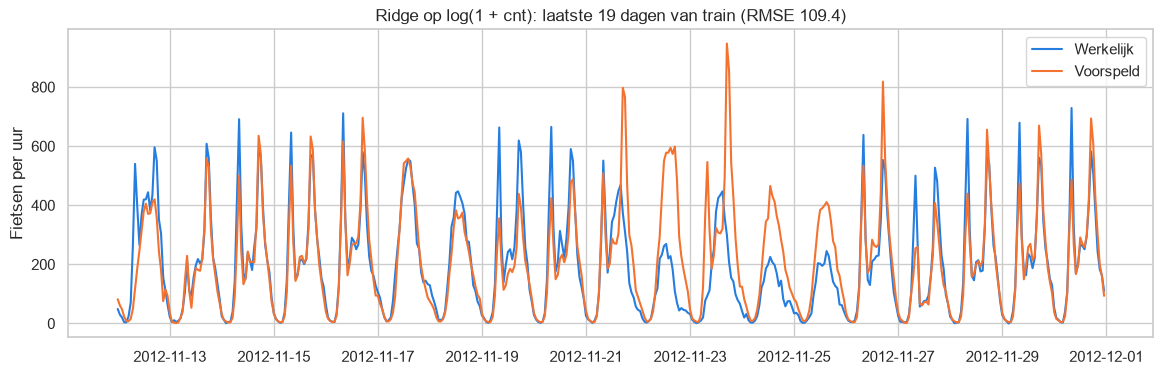

In [89]:
beste_lineair = tester.overview()["model"].iloc[0]
tester.plot_last_fold(beste_lineair, train_dates)

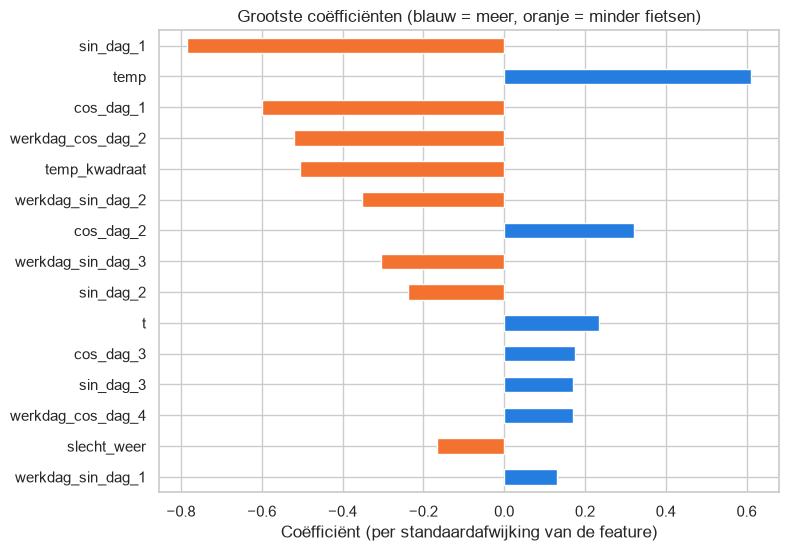

Coëfficiënten precies 0: 0 van 56


In [90]:
def plot_coefficients(pipeline, cols, top=15):
    """De grootste coëfficiënten (na standaardiseren) van een lineair model."""
    # Bij het log-model zit de pipeline in regressor_
    if hasattr(pipeline, "regressor_"):
        pipeline = pipeline.regressor_
    coef = pd.Series(pipeline[-1].coef_, index=cols)
    grootste = coef.reindex(coef.abs().sort_values().index).tail(top)
    kleuren = [BLUE if c > 0 else ORANGE for c in grootste]
    grootste.plot(kind="barh", color=kleuren, figsize=(8, 6))
    plt.title("Grootste coëfficiënten (blauw = meer, oranje = minder fietsen)")
    plt.xlabel("Coëfficiënt (per standaardafwijking van de feature)")
    plt.show()
    print(f"Coëfficiënten precies 0: {(coef == 0).sum()} van {len(coef)}")


plot_coefficients(*tester.models[beste_lineair])

#### Resultaten

**Wat zien we?** OLS, Ridge en Lasso scoren bijna hetzelfde (RMSE 93,8, 93,7 en 93,8). Regularisatie helpt hier dus weinig. Dat komt doordat we veel data hebben (ruim 16.000 uren) tegenover 56 features, waardoor het model weinig overfit. De beste $\alpha$ voor Lasso is heel klein (0,01) en Lasso zet maar 1 van de 56 features op 0.

Het model op $\log(1 + cnt)$ is gemiddeld veel beter (RMSE 77,3). Het gewone model voorspelt 's nachts gemiddeld zo'n 21 fietsen te veel en komt in sommige uren zelfs onder de 0 uit. Het log-model zit 's nachts er maar ongeveer 3 naast en kan nooit negatief worden, omdat de effecten als percentage werken.

Per fold zien we wel een groot verschil:

| Fold | Periode | OLS | Ridge op log(1 + cnt) |
|---|---|---|---|
| 1 | 28-08 t/m 15-09 | 94,8 | 67,8 |
| 2 | 16-09 t/m 04-10 | 98,2 | 68,4 |
| 3 | 05-10 t/m 23-10 | 80,8 | 72,6 |
| 4 | 24-10 t/m 11-11 | 90,1 | 68,1 |
| 5 | 12-11 t/m 30-11 | 105,3 | 109,4 |

In de laatste fold (eind november) scoren beide modellen veel slechter, en het log-model zelfs iets slechter dan OLS. Die periode is kouder en rustiger dan de rest van de trainingsdata, en Thanksgiving (22 november) valt erin. Omdat december het meest op deze periode lijkt, kan de Kaggle-score tegenvallen.

De grootste coëfficiënten zijn `sin_dag_1`, `temp` en `cos_dag_1`. Dat past bij de EDA: het tijdstip van de dag (het dagpatroon) en de temperatuur bepalen het meest hoeveel fietsen er worden gehuurd. `temp_kwadraat` heeft een negatieve coëfficiënt, dus als het té warm wordt, gaat het aantal weer omlaag. `t` is positief: de verhuur groeit door de tijd heen, net als de trend in 3.2.

Kaggle-score van dit model: **[ ]**

### 4.3 Ensemble model

#### Uitleg
_(wiskundige uitleg)_
#### Resultaten

### 4.4 Model 3 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.5 Model 4 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.6 Model 5 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.7 SARIMA(X)

#### Uitleg
#### Resultaten

### 4.8 Tweede tijdseriemodel (eigen keuze)

#### Uitleg
#### Resultaten

### 4.9 Hybride model

#### Uitleg
#### Resultaten

### 4.10 Voorspellingen voor Kaggle

## 5. Bevindingen

### 5.1 Samenvatting

### 5.2 Overzicht resultaten

| Model | Beste parameters | RMSE (CV) | RMSE Kaggle |
|---|---|---|---|
| Lineaire regressie | | | |
| Ensemble model | | | |
| Model 3 | | | |
| Model 4 | | | |
| Model 5 | | | |
| SARIMA(X) | | | |
| Tijdseriemodel 2 | | | |
| Hybride model | | | |

### 5.3 Welk model presteert het beste?

### 5.4 Kaggle-scores en verbeteringen

| Submission | Datum | Model / wijziging | RMSE Kaggle |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |

## 6. Conclusie en aanbevelingen

### 6.1 Welke features hebben de meeste invloed?

### 6.2 Aansluiting bij de EDA

### 6.3 Advies aan CityBike

### 6.4 Welk model adviseren wij en waarom?

## 7. Referenties